# Preprocessing, Augmentasi, dan Baseline: Sentimen Publik terhadap Raffi Ahmad

**Nama:** Raphael Angelo Adikara Purnama
**NIM:** 164241055
**Mata kuliah:** Natural Language Processing (UAS)
**Topik:** Klasifikasi sentimen publik terhadap Raffi Ahmad setelah kasus "mahasiswa bayaran" di Bundaran HI (29 Oktober 2026)

Notebook ini menyiapkan teks untuk semua model, membuat data augmentasi untuk kelas positif, lalu melatih baseline. Datanya `data/05_final/dataset_model.csv` dari `labeling/finalize.py`, yang sudah punya label akhir dan pembagian 5 fold.

Ada beberapa perubahan dari versi sebelumnya setelah konsultasi dosen:

1. **Target biner dihapus.** Sebelumnya saya juga melatih target negatif lawan bukan negatif, karena kelas positif sangat sedikit. Dosen menyarankan tetap 3 kelas dan menambah data positif lewat augmentasi.
2. **Augmentasi kelas positif** dari dua sumber: komentar positif di akun Instagram Raffi sendiri (jalur B) pada rentang waktu yang sama, dan parafrase hasil back-translation. Setiap model dibandingkan sebelum dan sesudah augmentasi.
3. **Istilah "konteks" diganti "judul"**, dan contoh datanya ditampilkan supaya jelas apa yang dibaca model.
4. **Preprocessing untuk model BERT tidak lagi memakai lowercase**, dan emoji diubah menjadi kata bahasa Indonesia, bukan bahasa Inggris.

In [1]:
import re
import sys
import json
import warnings
import emoji
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*converge.*")
pd.set_option("display.max_colwidth", 110)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

ROOT = Path.cwd().parent
RES, FIG, FINAL = ROOT / "resources", ROOT / "figures", ROOT / "data" / "05_final"
HASIL = ROOT / "data" / "06_baseline"
HASIL.mkdir(parents=True, exist_ok=True)

# fungsi pengelompokan yang sama dengan yang dipakai finalize.py saat membuat fold
sys.path.insert(0, str(ROOT / "labeling"))
from finalize import kunci, grup

df = pd.read_csv(FINAL / "dataset_model.csv", dtype={"sumber_id": str})
df["judul"] = df.judul.fillna("")
df["kunci"] = df.text.map(kunci)
df["grup"] = grup(df)
print(df.shape)
print(df.label.value_counts().to_string())
pd.crosstab(df.fold, df.label, margins=True)

(3329, 21)
label
negatif    2206
netral     1039
positif      84


label,negatif,netral,positif,All
fold,,,,
0,441,208,17,666
1,441,208,17,666
2,442,208,16,666
3,441,207,17,665
4,441,208,17,666
All,2206,1039,84,3329


Dataset berisi 3.329 teks: 2.206 negatif (66,3%), 1.039 netral (31,2%), dan 84 positif (2,5%). Label ini sudah final. Teks yang tidak disepakati bulat ketiga AI dinilai lengkap oleh 3 orang (review 3 lapis, 881 kartu), lalu diambil suara terbanyak, dan 29 kartu yang ketiganya berbeda diputus lewat diskusi tim. Kolom `fold` dibuat oleh `labeling/finalize.py`. Tiap fold berisi 665 sampai 666 teks dengan 16 atau 17 teks positif.

## Apa yang dimaksud "judul"

Di versi sebelumnya saya menyebutnya "konteks". Isinya adalah teks unggahan tempat sebuah komentar ditulis, jadi istilah "judul" lebih tepat. Isi kolom `judul` berbeda per platform karena tiap platform punya bentuk unggahan yang berbeda:

| platform | isi kolom `judul` |
|---|---|
| YouTube | judul video, diawali nama channel |
| Instagram | caption unggahan, diawali nama akun pemilik |
| TikTok | deskripsi video, diawali nama kreator |
| X | isi tweet yang dikutip atau dibalas. Kalau tweet induknya tidak ikut ter-scrape, judulnya hanya keterangan bahwa tweet ini membalas akun lain. Tweet yang berdiri sendiri tidak punya judul |

Judul perlu karena banyak komentar yang baru jelas maknanya kalau tahu unggahannya. "14 M" atau "pantes aja" tidak berarti apa-apa tanpa tahu bahwa videonya membahas kontrak Rp14,7 miliar. Tabel di bawah memperlihatkan contoh data per platform, persis seperti yang dibaca annotator dan model.

In [2]:
contoh_judul = pd.concat([g[g.butuh_konteks].sample(2, random_state=3)
                          for _, g in df[df.judul.str.len() > 0].groupby("platform")])
contoh_judul[["platform", "judul", "text", "label"]].assign(judul=lambda x: x.judul.str[:110])

,platform,judul,text,label
566,instagram,Caption unggahan @kabinetrakyatri: EKSPRESI SAYANG RAKYAT KE AA RAFFI AHMAD Social experiment di video ini...,Brp kali plak plok ituuh 😂,negatif
213,instagram,Caption unggahan @isseinugroho: RAKYAT !!!! MUAK BANGET sama Willie Salim & Raffi Ahmad #fyp #reelsindones...,Wkwk jadi tau kan siapa yang mahasewa?,netral
2899,tiktok,Deskripsi video @arunalif_: Rafi ahmad meramaikan hari sumpah pemuda di tanggal 29 oktober. Horang kayaa.....,"pagi"" jadi ngakak",netral
996,tiktok,Deskripsi video @triana.cute: ICW Bongkar Raffi Ahmad Terima Kontrak Jasa Influencer Rp14 Miliar dari APBN...,wajib di Audit.,negatif
1799,x,"Membalas tweet: Yg punya akun masih tidur. Percuma bangun tapi ga produktif, percuma kerja tapi yg kaya ra...","@user Yang kaya Raffi Ahmad, yang capek kita.",negatif
1184,x,"Tweet yang dikutip: Ternyata bener ya vibes tu ga bisa dibeli, bolehlah mereka pake almet kita tp tetep aj...","When sahabat mu nasehati mu momen ketika Raffi Ahmad dinasehati oleh Irfan Hakim untuk jadi Artis, host saja",negatif
2283,youtube,Judul video Tribunnews: Raffi Ahmad Minta Maaf seusai Gaduh Deklarasi Sumpah Pemuda Bundaran HI: Saya Hadi...,Hati hati jangan ceroboh harus bisa menempatkan Mahasiswa snngat berjuang tak kenal lelah,negatif
3198,youtube,Judul video Pandji Pragiwaksono: 14M UNTUK RAFFI,Bang panji masih ingat tidak ada yang dihukum karna buat video untuk 10 desa seharga 200jt karna dianggap ...,netral


Contoh di atas memperlihatkan kenapa judul dibutuhkan. "wajib di Audit." tidak menyebut siapa pun, tapi judulnya "ICW Bongkar Raffi Ahmad Terima Kontrak Jasa Influencer Rp14 Miliar dari APBN", jadi yang diminta diaudit adalah kontrak Raffi. "Wkwk jadi tau kan siapa yang mahasewa?" juga baru jelas sasarannya setelah membaca caption "MUAK BANGET sama Willie Salim & Raffi Ahmad". Contoh X memperlihatkan keterbatasan judul di X: judulnya hanya tweet induk yang dibalas atau dikutip, dan kalau tweet induknya tidak ikut ter-scrape, judulnya hanya keterangan bahwa tweet ini membalas akun lain.

In [3]:
print("teks yang punya judul:", f"{df.judul.str.len().gt(0).mean():.1%}")
print(df.assign(punya_judul=df.judul.str.len().gt(0)).groupby("platform").punya_judul.mean().round(3).to_string())

teks yang punya judul: 81.8%
platform
instagram    1.000
tiktok       1.000
x            0.521
youtube      1.000


Semua komentar Instagram, TikTok, dan YouTube punya judul, sedangkan di X hanya 52,1% (tweet yang mengutip atau membalas). Secara keseluruhan 81,8% teks punya judul.

In [4]:
panjang = df.text.str.split().str.len()
print("jumlah kata per teks:")
print(panjang.describe(percentiles=[.25, .5, .75, .95]).round(1).to_string())
print()
print("teks yang memuat mention :", round(df.text.str.contains("@").mean() * 100, 1), "%")
print("teks yang memuat emoji   :", round(df.text.map(lambda t: emoji.emoji_count(t) > 0).mean() * 100, 1), "%")
print("teks yang memuat hashtag :", round(df.text.str.contains("#").mean() * 100, 1), "%")
print("teks dengan kata KAPITAL :", round(df.text.str.contains(r"\b[A-Z]{4,}\b").mean() * 100, 1), "%")
print("ditandai butuh judul     :", round(df.butuh_konteks.mean() * 100, 1), "%")

jumlah kata per teks:
count    3329.0
mean       21.3
std        33.6
min         1.0
25%         6.0
50%        12.0
75%        23.0
95%        62.0
max       509.0

teks yang memuat mention : 16.9 %


teks yang memuat emoji   : 27.7 %
teks yang memuat hashtag : 3.0 %
teks dengan kata KAPITAL : 19.0 %
ditandai butuh judul     : 50.8 %


Teksnya pendek. Setengah teks hanya 12 kata atau kurang, dan 95% di bawah 63 kata. Sebanyak 27,7% teks memuat emoji, jadi cara emoji diubah memang berpengaruh. Ada 19,0% teks yang memuat kata kapital minimal 4 huruf, misalnya "BOIKOT" atau "MAMPUS". Inilah alasan lowercase tidak dipakai untuk model BERT. Separuh teks (50,8%) ditandai annotator butuh judul supaya maknanya jelas.

## Preprocessing

Model yang berbeda butuh teks yang berbeda, jadi preprocessing dibagi tiga tingkat:

1. **Ringan**, dipakai semua model: mention jadi `@user`, URL dibuang, tanda `#` dibuang tapi katanya tetap, huruf yang diulang tiga kali atau lebih dipendekkan ("bangettt" jadi "banget"). Huruf besar dan emoji tidak diubah.
2. **Lengkap**, khusus TF-IDF: ringan + huruf kecil, emoji jadi token (`emo_wajah_muntah`), variasi tawa ("wkwk", "hahaha") disamakan jadi `tawa`, slang dinormalisasi dengan kamus 711 kata, lalu stopword dibuang dengan kata negasi tetap disimpan. TF-IDF hanya menghitung kata, jadi "Boikot", "boikot", dan "BOIKOT" harus disamakan supaya terhitung sebagai kata yang sama.
3. **BERT**, untuk IndoBERTweet, IndoBERT, XLM-R, embedding, dan BiLSTM: ringan + emoji diubah menjadi kata bahasa Indonesia (😂 jadi "wajah gembira berurai air mata"). **Tidak ada lowercase**. Model transformer membaca kalimat utuh dan punya tokenizer sendiri, jadi teks dikirim sedekat mungkin dengan aslinya. Kalau model-nya *cased* (XLM-R), huruf kapital bisa dipakai sebagai sinyal, misalnya "MAMPUS LU" yang ditulis kapital. Kalau model-nya *uncased*, tokenizer-nya sendiri yang mengubah ke huruf kecil. Emoji diubah ke bahasa Indonesia karena modelnya dilatih dari teks Indonesia, jadi kata Indonesia lebih mungkin sudah dikenal.

In [5]:
slang = json.load(open(RES / "slang_map.json", encoding="utf-8"))
NEGASI = {"tidak", "tdk", "gak", "ga", "gk", "nggak", "ngga", "enggak", "engga", "g", "bukan", "bkn",
          "jangan", "jgn", "belum", "blm", "tak", "kurang"}
stopword = set(open(RES / "stopwords.txt", encoding="utf-8").read().split()) - NEGASI
print("kamus slang:", len(slang), "| stopword:", len(stopword))


def bersih_ringan(t):
    t = str(t)
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"@\w+", "@user", t)
    t = re.sub(r"#(\w+)", r"\1", t)
    t = re.sub(r"([a-zA-Z])\1{2,}", r"\1", t)
    return re.sub(r"\s+", " ", t).strip()


def untuk_bert(t):
    """Ringan + emoji jadi kata bahasa Indonesia. Huruf besar tidak diubah."""
    t = emoji.demojize(bersih_ringan(t), language="id", delimiters=(" ", " "))
    return re.sub(r"\s+", " ", t.replace("_", " ")).strip()


def ke_token(t):
    t = bersih_ringan(t).lower()
    t = emoji.demojize(t, language="id", delimiters=(" emo_", " "))
    t = re.sub(r"\b(?:wk)+w?\b|\b(?:ha){2,}h?\b|\b(?:he){2,}h?\b|\b(?:xi){2,}\b", " tawa ", t)
    t = re.sub(r"[^a-z0-9_@ ]", " ", t)
    return " ".join(slang.get(w, w) for w in t.split()).split()


stemmer = StemmerFactory().create_stemmer()
_cache = {}


def stem(w):
    if w.startswith("emo_") or w == "@user":
        return w
    if w not in _cache:
        _cache[w] = stemmer.stem(w)
    return _cache[w]


def bersih_lengkap(t, buang_stop=True, pakai_stem=False):
    tok = ke_token(t)
    if buang_stop:
        tok = [w for w in tok if w not in stopword]
    if pakai_stem:
        tok = [stem(w) for w in tok]
    return " ".join(tok)


def isi_judul(t):
    # buang awalan "Caption unggahan @akun:" atau "Judul video channel:" supaya yang tersisa isinya saja
    return re.sub(r"^[^:]{0,60}:\s*", "", str(t))


def siapkan(d):
    d = d.copy()
    d["teks_ringan"] = d.text.map(bersih_ringan)
    d["teks_bert"] = d.text.map(untuk_bert)
    d["teks_lengkap"] = d.text.map(bersih_lengkap)
    d["judul_ringan"] = d.judul.fillna("").map(lambda t: bersih_ringan(isi_judul(t)))
    d["judul_bert"] = d.judul.fillna("").map(lambda t: untuk_bert(isi_judul(t)))
    d["judul_lengkap"] = d.judul.fillna("").map(lambda t: bersih_lengkap(isi_judul(t)))
    return d


df = siapkan(df)
contoh = df[df.text.str.contains("😂|🤮|😭") & df.text.str.contains(r"[A-Z]{3,}")].head(3)
contoh = pd.concat([contoh, df[df.text.str.len().between(40, 90)].sample(2, random_state=7)])
contoh[["text", "teks_bert", "teks_lengkap"]]

kamus slang: 711 | stopword: 430


,text,teks_bert,teks_lengkap
5,Tampang-tampang NASAKOM 😂😂😂😂😂,Tampang-tampang NASAKOM wajah gembira berurai air mata wajah gembira berurai air mata wajah gembira berura...,tampang tampang nasakom emo_wajah_gembira_berurai_air_mata emo_wajah_gembira_berurai_air_mata emo_wajah_ge...
8,KAMI ADALAH PUTERA DAN PUTERI BAYARAN....!!!!😂😂😂😂😂😂😂👏👏👏👏,KAMI ADALAH PUTERA DAN PUTERI BAYARAN....!!!! wajah gembira berurai air mata wajah gembira berurai air mat...,putera puteri bayaran emo_wajah_gembira_berurai_air_mata emo_wajah_gembira_berurai_air_mata emo_wajah_gemb...
12,kocaak ini jadi kayak EVENT tandingan ahahaha sakit jiwa Pemerintah aslik 😂😂😂🔥🔥,kocaak ini jadi kayak EVENT tandingan ahahaha sakit jiwa Pemerintah aslik wajah gembira berurai air mata w...,kocaak kayak event tandingan ahahaha sakit jiwa pemerintah aslik emo_wajah_gembira_berurai_air_mata emo_wa...
3293,Strateginya Militer banget yah. gk call out juga tuh,Strateginya Militer banget yah. gk call out juga tuh,strateginya militer banget ya enggak call out tuh
1916,Barusan ditelpon RAFFI AHMAD apakah perlu telpon balik apa tidak?,Barusan ditelpon RAFFI AHMAD apakah perlu telpon balik apa tidak?,barusan ditelpon raffi ahmad telpon tidak


Contoh di atas memperlihatkan perbedaan ketiga versi. Di `teks_bert`, "KAMI ADALAH PUTERA DAN PUTERI BAYARAN" tetap kapital dan 😂 menjadi "wajah gembira berurai air mata". Di `teks_lengkap` untuk TF-IDF, semua menjadi huruf kecil, emoji menjadi satu token `emo_wajah_gembira_berurai_air_mata`, stopword seperti "adalah" dan "dan" dibuang, dan slang dinormalisasi, misalnya "gk" menjadi "enggak" dan "yah" menjadi "ya".

Sel berikut menunjukkan apa yang benar-benar diterima model untuk input **teks + judul**. TF-IDF membuat dua vektor terpisah (satu dari teks, satu dari judul) lalu menggabungkannya, dengan bobot judul setengah dari teks. Model BERT menerima keduanya sebagai pasangan kalimat: `[CLS] teks [SEP] judul [SEP]`, jadi model tahu mana komentar dan mana unggahannya.

In [6]:
r = df[df.butuh_konteks & df.platform.eq("youtube")].iloc[0]
print("teks asli        :", r.text)
print("judul asli       :", r.judul)
print()
print("TF-IDF teks      :", r.teks_lengkap)
print("TF-IDF judul     :", r.judul_lengkap)
print()
print("BERT (pasangan)  : [CLS]", r.teks_bert, "[SEP]", r.judul_bert[:150], "[SEP]")
print("label            :", r.label)

teks asli        : selain kru acara dan preman setempat, yang datang adalah yang mau update liputan kalau acaranya sepi 🤣🤣🤣
judul asli       : Judul video Bimo Hakito: RAFFI AHMAD MAKIN TERPOJOK! GA BAKAL NYANGKA JADI BEGINI, TIBA-TIBA DIDEMO PAS BAWA ACARA!

TF-IDF teks      : kru acara preman update liputan acaranya sepi emo_tertawa_terbahak bahak emo_tertawa_terbahak bahak emo_tertawa_terbahak bahak
TF-IDF judul     : raffi ahmad terpojok enggak menyangka didemo pas bawa acara

BERT (pasangan)  : [CLS] selain kru acara dan preman setempat, yang datang adalah yang mau update liputan kalau acaranya sepi tertawa terbahak-bahak tertawa terbahak-bahak tertawa terbahak-bahak [SEP] RAFFI AHMAD MAKIN TERPOJOK! GA BAKAL NYANGKA JADI BEGINI, TIBA-TIBA DIDEMO PAS BAWA ACARA! [SEP]
label            : negatif


Komentar ini tidak menyebut Raffi sama sekali ("yang datang adalah yang mau update liputan kalau acaranya sepi"). Labelnya negatif karena judulnya "RAFFI AHMAD MAKIN TERPOJOK! ... TIBA-TIBA DIDEMO PAS BAWA ACARA!", jadi yang diejek sepi adalah acara yang dibawakan Raffi. Model teks saja tidak punya cara untuk mengetahuinya. Untuk BERT, judul ditaruh setelah `[SEP]` dan huruf kapitalnya tetap.

In [7]:
def ukuran_kosakata(kolom):
    return len(set(" ".join(kolom).split()))


df["teks_tanpa_stop"] = df.text.map(lambda t: bersih_lengkap(t, buang_stop=False))
df["teks_stem"] = df.text.map(lambda t: bersih_lengkap(t, pakai_stem=True))
df["teks_lower"] = df.text.map(lambda t: bersih_ringan(t).lower())
versi = {"ringan + lowercase": "teks_lower", "+ emoji, tawa, slang": "teks_tanpa_stop",
         "+ buang stopword (versi utama)": "teks_lengkap", "+ stemming": "teks_stem"}
pd.DataFrame([{"versi": v, "ukuran kosakata": ukuran_kosakata(df[k]),
               "rata2 token per teks": round(df[k].str.split().str.len().mean(), 1)} for v, k in versi.items()])

,versi,ukuran kosakata,rata2 token per teks
0,ringan + lowercase,15251,21.3
1,"+ emoji, tawa, slang",10141,21.9
2,+ buang stopword (versi utama),9734,14.8
3,+ stemming,7469,14.8


Normalisasi emoji, tawa, dan slang memangkas kosakata dari 15.251 menjadi 10.141 kata unik. Membuang stopword hanya mengurangi kosakata sedikit (9.734), tapi rata-rata panjang teks turun dari 21,9 menjadi 14,8 token. Stemming memangkas kosakata paling banyak (7.469). Dampaknya ke model diuji di bagian ablation.

## Augmentasi kelas positif

Kelas positif hanya 84 teks, jadi tiap fold uji hanya punya 16 atau 17 teks positif. Model sulit belajar dari contoh sesedikit itu. Saran dosen adalah menambah data positif, bukan mengubah target menjadi biner. Ada dua sumber:

**1. Komentar positif dari akun Raffi (jalur B).** Bu Mar menyarankan komentar dari akun Raffi sendiri boleh dipakai untuk menambah contoh positif, selama rentang waktunya sesuai. Komentar ini sudah ada (jalur B, 22 Oktober sampai 14 November) dan sudah dilabeli dengan cara yang sama. Di `finalize.py` saya hanya mengambil yang label akhirnya positif, bukan buzzer, dan akun maupun teksnya tidak muncul di data utama. Syarat terakhir penting: kalau akun yang sama ada di data uji, model bisa terlihat bagus karena hafal gaya akun itu.

**2. Parafrase back-translation.** Teks positif diterjemahkan ke bahasa Inggris dengan model MarianMT `Helsinki-NLP/opus-mt-id-en` (dengan sampling supaya hasilnya bervariasi), lalu diterjemahkan kembali dengan `opus-mt-en-id`. Hasilnya kalimat dengan makna yang sama tapi susunan kata berbeda. Prosesnya dijalankan di Kaggle (`augmentasi/kaggle_bt/back_translation.py`) untuk semua teks yang pernah dinilai positif oleh minimal satu annotator atau reviewer, supaya tidak perlu diulang kalau label berubah setelah review 3 lapis. Yang dipakai saat training hanya parafrase dari teks yang label akhirnya positif.

Kedua sumber **hanya dipakai di fold latih**. Data uji tetap teks jalur A asli, supaya skor sebelum dan sesudah augmentasi diukur di data yang sama.

In [8]:
bt = pd.read_csv(FINAL / "augmentasi_bt_mentah.csv")


def alasan_buang(r):
    a, p = r.text_asli, str(r.parafrase)
    if re.search(r"[♪▪]", p):
        return "simbol aneh dari model"
    if re.search(r"(\w-){4,}|(\w)\2{5,}", p):
        return "pengulangan karakter"
    if ("@user" in a and "@user" not in p) or re.search(r"\bBu\w*di\b", p):
        return "mention @user rusak"
    na, npar = len(a.split()), len(p.split())
    if na >= 6 and npar < 0.5 * na:
        return "terpotong lebih dari separuh"
    if npar < 2:
        return "terlalu pendek"
    return ""


bt["alasan_buang"] = bt.apply(alasan_buang, axis=1)
print("parafrase mentah:", len(bt), "dari", bt.id.nunique(), "teks")
print(bt.alasan_buang.replace("", "lolos").value_counts().to_string())
cek = pd.read_csv(ROOT / "augmentasi" / "cek_manual_bt.csv")
print("\ncek manual 40 sampel acak yang lolos saringan:", cek.makna_tetap.value_counts().to_dict())
cek[cek.makna_tetap.eq("tidak")][["text_asli", "parafrase", "catatan"]]

parafrase mentah: 484 dari 177 teks
alasan_buang
lolos                           344
mention @user rusak              61
terpotong lebih dari separuh     51
simbol aneh dari model           19
pengulangan karakter              7
terlalu pendek                    2

cek manual 40 sampel acak yang lolos saringan: {'ya': 33, 'tidak': 7}


,text_asli,parafrase,catatan
2,hnya Krn beda pilihan 😭,Bagaimana kau tahu perbedaan antara pilihan t-t-t-t-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-n-...,"teks rusak, huruf berulang tanpa makna"
12,"Yang hujat belum tentu sumbangan , donasi,sedekahnya sebermanfaat dia 😇","Penghujatan tidak selalu merupakan sumbangan, sumbangan, sedekah yang berguna seperti dia.",makna membela berubah jadi kalimat yang tidak jelas
13,@user emang sombong si songong ini ..klo rafi baek dia ngak kaya bininye @user,@user adalah lagu ini sombong .. klo raci baik dia tidak sekaya budi bininye,"kalimat rusak, sasaran tidak jelas"
17,Semangat bg... dunia akan berlalu.. mwehhhh,Roh dunia sedang berlalu.. mwehhhh,"kata 'semangat' hilang, dukungan tidak terbaca"
26,"@user @user aku setuju Aza Out ae timbang gak onok prestasi, misal aku usul Raffi Ahmad gimana cak @user ?...","@user @user saya setuju Aza Out ae weak no feat, let me say Raffi Ahmad how about @user????","bercampur bahasa Inggris, maknanya tidak jelas"
37,"Ujian orang baik ,, sehat sehat a Raffi 😇","Tes orang baik, sehat. Raffi sangat berbahaya.",makna berbalik: 'sehat sehat a Raffi' jadi 'Raffi sangat berbahaya'
39,MAMPUS LU DIKULITI NETIZEN 😂,MAMPUS LU FOLLOWED NETIZEN rush,"'DIKULITI' jadi 'FOLLOWED', makna hilang"


Back-translation menghasilkan 484 parafrase dari 177 teks. Lima parafrase terakhir berasal dari 2 teks yang dulu belum pernah dinilai positif, sehingga dijalankan tersendiri di Kaggle (`augmentasi/siapkan_bt_tambahan.py`). Kedua teks itu akhirnya dikoreksi menjadi negatif, jadi parafrasenya tidak terpakai. Saringan otomatis membuang 140 parafrase yang jelas rusak: 61 karena mention `@user` berubah (MarianMT kadang menerjemahkan nama pengganti sementara menjadi kata lain seperti "Burdi"), 51 karena terpotong lebih dari separuh, 19 karena muncul simbol aneh seperti ♪ dan ▪, 7 karena pengulangan karakter, dan 2 karena terlalu pendek. Tersisa 344 parafrase.

Saringan otomatis tidak bisa mengecek makna, jadi saya membaca 40 parafrase acak yang lolos. Hasilnya 33 dari 40 (82,5%) masih mempertahankan sikap positif ke Raffi, misalnya "sabar raffi ahmad masi banyak orang yg percaya sm km" menjadi "bersabar, Raffi ahmad masih banyak orang yang percaya padamu". Sisanya 7 rusak, dan yang paling berbahaya adalah makna yang berbalik, seperti "Ujian orang baik ,, sehat sehat a Raffi" menjadi "Raffi sangat berbahaya". Jadi sekitar 1 dari 6 parafrase kemungkinan membawa label yang salah. Ini kelemahan back-translation untuk teks gaul, dan dampaknya akan terlihat dari perbandingan dengan dan tanpa parafrase di bawah. Daftar lengkap hasil cek ada di `augmentasi/cek_manual_bt.csv`.

In [9]:
bt = bt[bt.alasan_buang.eq("")]
jb = pd.read_csv(FINAL / "augmentasi_jalur_b.csv").fillna({"judul": ""})
label_akhir = pd.concat([df.set_index("id").label, jb.set_index("id").label])
judul_asal = pd.concat([df.set_index("id").judul, jb.set_index("id").judul])
fold_asal = df.set_index("id").fold
grup_asal = pd.concat([df.set_index("id").grup, ("b_" + jb.author_hash.fillna(jb.id)).set_axis(jb.id)])

bt = bt[bt.id.map(label_akhir).eq("positif")]  # hanya parafrase dari teks yang label akhirnya positif
aug = pd.concat([
    pd.DataFrame({"id": jb.id, "id_asal": jb.id, "sumber": "jalur_b", "text": jb.text, "judul": jb.judul}),
    pd.DataFrame({"id": bt.id_aug, "id_asal": bt.id, "sumber": np.where(bt.kelompok.eq("utama"), "bt_utama", "bt_jalur_b"),
                  "text": bt.parafrase, "judul": bt.id.map(judul_asal)}),
], ignore_index=True)
# pelabelan terarah dari teks cadangan (labeling/terarah/), hanya kalau labelnya sudah final
f_terarah = FINAL / "augmentasi_terarah.csv"
if f_terarah.exists():
    tr = pd.read_csv(f_terarah).fillna({"judul": ""})
    aug = pd.concat([aug, pd.DataFrame({"id": tr.id, "id_asal": tr.id, "sumber": "terarah", "text": tr.text,
                                        "judul": tr.judul})], ignore_index=True)
    grup_asal = pd.concat([grup_asal, ("t_" + tr.author_hash.fillna(tr.id)).set_axis(tr.id)])
aug["label"] = "positif"
aug["fold_asal"] = aug.id_asal.map(fold_asal).fillna(-1).astype(int)  # -1: berasal dari jalur B, aman untuk semua fold
aug["grup"] = aug.id_asal.map(grup_asal)
aug = siapkan(aug)
print(aug.sumber.value_counts().to_string())
aug.groupby("sumber").sample(2, random_state=1)[["sumber", "text", "judul"]].assign(judul=lambda x: x.judul.str[:60])

sumber
bt_utama      172
bt_jalur_b     81
jalur_b        42
terarah        32


,sumber,text,judul
128,bt_jalur_b,Selama aku tahu orang baik dan itu sudah cukup bagiku saat aku menikah dia datang saat hujan deras.,Caption unggahan @raffinagita1717: Ajja ... Makasih yaa pelu
92,bt_jalur_b,"Dari Rafi, aku belajar bahwa nama teman mengingatkan satu sama lain tentang lingkup privasi, setiap kali t...","Caption unggahan @raffinagita1717: Ya Allah, aku titipkan su"
225,bt_utama,anggap saja ini uang pajak Raffi ahmad kakak disanalah dia membayar pajaknya dan kemudian diterima lagi ak...,Deskripsi video @geraldvincentt: Duit pajak rakyat 14 MILYAR
257,bt_utama,"Ini adalah ketika kita turun, orang-orang yang mengatakan siapa teman dan siapa yang terlihat aman akan te...",Judul video Tribunnews: Deretan Artis & Konten Kreator Kecam
1,jalur_b,Bnyk yg menghujat tp insyaAllah banyak juga yg masih dukung @user Allah ngasih ujian buat naek level selan...,Caption unggahan @raffinagita1717: Menghadiri Sidang Kabinet
2,jalur_b,Semangat Terus a🔥🔥🔥,Caption unggahan @raffinagita1717: Menghadiri Sidang Kabinet
304,terarah,"tapi aku masih percaya sama Raffi Ahmad, dia orang baik tulus juga ko, sabar ya Aa","Deskripsi video @suara.angkasa: Nasib raffi ahmad, satu pers"
326,terarah,udah lah Rafi Ahmad sblm JD UKP dia pekerja keras hingga dia jd seperti sekarang.Jangan menghujat orang yg...,Deskripsi video @dailyinsky: Dimafiin ga guys???? #raffiahma


Data augmentasi berisi 295 teks positif: 42 komentar jalur B, 172 parafrase dari teks positif data utama, dan 81 parafrase dari komentar jalur B. Hanya parafrase dari teks yang label akhirnya positif yang dipakai. Judul parafrase disamakan dengan judul teks aslinya. Kolom `fold_asal` menyimpan fold teks asli, jadi parafrase dari teks di fold uji bisa dibuang saat training. Komentar jalur B dan parafrasenya diberi `fold_asal` -1, karena tidak ada di data uji mana pun.

In [10]:
simpan = ["id", "text", "judul", "teks_ringan", "teks_bert", "teks_lengkap", "judul_ringan", "judul_bert",
          "judul_lengkap", "label", "fold", "grup", "platform", "fase", "sub", "sarkasme", "butuh_konteks", "target_lain"]
df[simpan].to_csv(FINAL / "dataset_prepro.csv", index=False, encoding="utf-8-sig")
kolom_aug = ["id", "id_asal", "sumber", "text", "judul", "teks_ringan", "teks_bert", "teks_lengkap", "judul_ringan",
             "judul_bert", "judul_lengkap", "label", "fold_asal", "grup"]
aug[kolom_aug].to_csv(FINAL / "augmentasi_prepro.csv", index=False, encoding="utf-8-sig")
# salinan untuk dataset Kaggle (notebook 03 dan 04)
for f in ("dataset_prepro.csv", "augmentasi_prepro.csv"):
    (ROOT / "augmentasi" / "kaggle_data" / f).write_bytes((FINAL / f).read_bytes())
print(df[simpan].shape, aug[kolom_aug].shape)

(3329, 18) (327, 14)


Hasil preprocessing disimpan ke `data/05_final/dataset_prepro.csv` dan data augmentasi ke `augmentasi_prepro.csv`. Kedua berkas ini juga diunggah ke dataset Kaggle privat `raphaeladikara/uas-nlp-raffi-v2`, jadi notebook 03 dan 04 memakai preprocessing yang sama persis.

## Cara evaluasi

Targetnya 3 kelas (negatif, netral, positif). Metrik utamanya **macro-F1**, yaitu rata-rata F1 ketiga kelas dengan bobot sama. Akurasi tidak dipakai sebagai patokan, karena model yang selalu menebak negatif sudah mendapat akurasi sekitar 67%. F1 positif juga selalu dilaporkan, karena kelas inilah yang paling sulit dan yang menjadi alasan augmentasi.

Evaluasinya grouped 5-fold CV memakai kolom `fold`: latih di 4 fold, uji di 1 fold, ulang 5 kali. Satu akun dan teks identik selalu berada di fold yang sama. Hyperparameter dipilih dengan 3-fold CV di dalam fold latih saja (nested CV). Untuk varian augmentasi, data tambahan dimasukkan ke fold latih sebelum tuning, dan parafrase dari teks yang ada di fold uji dibuang.

In [11]:
LABEL = ["negatif", "netral", "positif"]
VARIAN = {"tanpa augmentasi": [], "jalur B": ["jalur_b"], "parafrase": ["bt_utama"],
          "jalur B + parafrase": ["jalur_b", "bt_utama", "bt_jalur_b"]}
if aug.sumber.eq("terarah").any():
    VARIAN["jalur B + terarah"] = ["jalur_b", "terarah"]


def evaluasi(buat_model, X, X_aug=None, varian="tanpa augmentasi", grid=None):
    pred = pd.Series(index=df.index, dtype=object)
    baris = []
    for k in range(5):
        latih, uji = (df.fold != k).values, (df.fold == k).values
        Xl, yl, gl = X[latih], df.label[latih], df.grup[latih]
        n_aug = 0
        if VARIAN[varian]:
            pilih = (aug.sumber.isin(VARIAN[varian]) & aug.fold_asal.ne(k)).values
            Xl, yl, gl = pd.concat([Xl, X_aug[pilih]]), pd.concat([yl, aug.label[pilih]]), pd.concat([gl, aug.grup[pilih]])
            n_aug = int(pilih.sum())
        model = buat_model()
        if grid:
            model = GridSearchCV(model, grid, scoring="f1_macro", n_jobs=-1,
                                 cv=StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=42))
            model.fit(Xl, yl, groups=gl)
        else:
            model.fit(Xl, yl)
        p = model.predict(X[uji])
        pred[uji] = p
        f1 = f1_score(df.label[uji], p, labels=LABEL, average=None, zero_division=0)
        baris.append({"fold": k, "n_aug": n_aug, "macro_f1": f1.mean(), "akurasi": accuracy_score(df.label[uji], p),
                      "balanced_acc": balanced_accuracy_score(df.label[uji], p),
                      **{f"f1_{c}": v for c, v in zip(LABEL, f1)}, "param": model.best_params_ if grid else None})
    return pd.DataFrame(baris), pred


hasil, prediksi = {}, {}


def catat(nama, input_, varian, tabel, pred):
    hasil[(nama, input_, varian)] = tabel
    prediksi[(nama, input_, varian)] = pred
    print(f"{nama:20s} | {input_:12s} | {varian:20s} | macro-F1 {tabel.macro_f1.mean():.3f} ± {tabel.macro_f1.std():.3f}"
          f" | F1 positif {tabel.f1_positif.mean():.3f}")


X = pd.DataFrame({"teks": df.teks_lengkap, "judul": df.judul_lengkap, "text": df.text})
X_aug = pd.DataFrame({"teks": aug.teks_lengkap, "judul": aug.judul_lengkap, "text": aug.text})

## Baseline 1 dan 2: tebak kelas terbanyak dan leksikon InSet

Dua baseline tanpa pembelajaran ini menjadi batas bawah. Yang pertama selalu menebak negatif. Yang kedua memakai leksikon InSet (Indonesia Sentiment Lexicon): skor kata positif dan negatif dijumlah, lalu skor di bawah 0 jadi negatif, di atas 0 jadi positif, dan 0 jadi netral. Kata negasi sebelum kata berbobot membalik tandanya. Keduanya tidak dilatih, jadi augmentasi tidak berpengaruh.

In [12]:
tabel, pred = evaluasi(lambda: DummyClassifier(strategy="most_frequent"), X)
catat("kelas terbanyak", "teks saja", "tanpa augmentasi", tabel, pred)

inset = pd.concat([pd.read_csv(RES / "inset_positive.tsv", sep="\t"), pd.read_csv(RES / "inset_negative.tsv", sep="\t")])
inset = inset.groupby("word").weight.sum().to_dict()
PEMBALIK = {"tidak", "enggak", "bukan", "jangan", "belum", "kurang", "tak"}


def skor_inset(teks):
    tok, skor, i = ke_token(teks), 0, 0
    while i < len(tok):
        for n in (3, 2, 1):
            frasa = " ".join(tok[i:i + n])
            if len(tok[i:i + n]) == n and frasa in inset:
                skor += -inset[frasa] if i > 0 and tok[i - 1] in PEMBALIK else inset[frasa]
                i += n
                break
        else:
            i += 1
    return skor


class Leksikon:
    def fit(self, X, y):
        return self

    def predict(self, X):
        s = X.text.map(skor_inset).values
        return np.select([s < 0, s > 0], ["negatif", "positif"], "netral")


tabel, pred = evaluasi(Leksikon, X)
catat("leksikon InSet", "teks saja", "tanpa augmentasi", tabel, pred)
df.assign(skor=df.text.map(skor_inset)).groupby("label").skor.describe().round(2)

kelas terbanyak      | teks saja    | tanpa augmentasi     | macro-F1 0.266 ± 0.000 | F1 positif 0.000


leksikon InSet       | teks saja    | tanpa augmentasi     | macro-F1 0.315 ± 0.014 | F1 positif 0.082


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
negatif,2206.0,-6.30,13.74,-219.0,-9.00,-3.0,0.0,24.0
netral,1039.0,-7.45,20.14,-327.0,-10.00,-3.0,1.0,62.0
positif,84.0,-5.17,16.37,-63.0,-13.25,-2.0,5.0,47.0


Tebak kelas terbanyak mendapat macro-F1 0,266 dengan F1 positif dan netral 0, walaupun akurasinya 0,663. Leksikon InSet hanya sedikit lebih baik (0,315). Tabel skor InSet menjelaskan kenapa: median skor ketiga kelas sama-sama negatif (-3 untuk negatif dan netral, -2 untuk positif). InSet mengukur nada kata, bukan sikap ke Raffi. Pembelaan yang marah ke pengkritik Raffi tetap mendapat skor negatif.

## Baseline 3: TF-IDF dengan Logistic Regression dan Linear SVM

Setiap teks diubah jadi vektor TF-IDF dari n-gram kata (1 sampai 2) dan n-gram huruf (3 sampai 5). N-gram huruf membantu untuk salah ketik dan slang ("rafi", "raffi", "raffy"). Untuk input teks + judul, judul dibuat vektor sendiri dengan bobot 0,5, karena isi komentar tetap yang utama. Klasifikasinya Logistic Regression dan Linear SVM dengan class weight seimbang.

Logistic Regression dijalankan untuk kedua input dan keempat varian augmentasi. Linear SVM hanya untuk tanpa augmentasi dan augmentasi lengkap, karena tujuannya hanya pembanding.

In [13]:
def fitur(pakai_judul):
    teks = FeatureUnion([
        ("kata", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("huruf", TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=2, sublinear_tf=True)),
    ])
    kolom, bobot = [("teks", teks, "teks")], {"teks": 1.0}
    if pakai_judul:
        kolom.append(("judul", TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), "judul"))
        bobot["judul"] = 0.5
    return ColumnTransformer(kolom, transformer_weights=bobot)


MODEL = {
    "TF-IDF + LogReg": (lambda: LogisticRegression(class_weight="balanced", max_iter=3000), {"clf__C": [0.3, 1, 3, 10]},
                        list(VARIAN)),
    "TF-IDF + LinearSVM": (lambda: LinearSVC(class_weight="balanced", random_state=42), {"clf__C": [0.03, 0.1, 0.3, 1]},
                           ["tanpa augmentasi", "jalur B + parafrase"]),
}
for nama, (clf, grid, daftar) in MODEL.items():
    for input_, pj in [("teks saja", False), ("teks + judul", True)]:
        for varian in daftar:
            buat = lambda clf=clf, pj=pj: Pipeline([("fitur", fitur(pj)), ("clf", clf())])
            tabel, pred = evaluasi(buat, X, X_aug, varian, grid)
            catat(nama, input_, varian, tabel, pred)

TF-IDF + LogReg      | teks saja    | tanpa augmentasi     | macro-F1 0.526 ± 0.032 | F1 positif 0.206


TF-IDF + LogReg      | teks saja    | jalur B              | macro-F1 0.551 ± 0.032 | F1 positif 0.269


TF-IDF + LogReg      | teks saja    | parafrase            | macro-F1 0.517 ± 0.031 | F1 positif 0.180


TF-IDF + LogReg      | teks saja    | jalur B + parafrase  | macro-F1 0.534 ± 0.030 | F1 positif 0.220


TF-IDF + LogReg      | teks saja    | jalur B + terarah    | macro-F1 0.561 ± 0.039 | F1 positif 0.293


TF-IDF + LogReg      | teks + judul | tanpa augmentasi     | macro-F1 0.584 ± 0.019 | F1 positif 0.302


... (4 outputs left out)

TF-IDF + LinearSVM   | teks saja    | tanpa augmentasi     | macro-F1 0.506 ± 0.032 | F1 positif 0.123


TF-IDF + LinearSVM   | teks saja    | jalur B + parafrase  | macro-F1 0.537 ± 0.028 | F1 positif 0.231


TF-IDF + LinearSVM   | teks + judul | tanpa augmentasi     | macro-F1 0.551 ± 0.026 | F1 positif 0.165


TF-IDF + LinearSVM   | teks + judul | jalur B + parafrase  | macro-F1 0.587 ± 0.021 | F1 positif 0.257


TF-IDF jauh di atas kedua baseline. Tanpa augmentasi, LogReg dengan teks saja mendapat 0,526 dan naik ke **0,584 ± 0,019** setelah judul ditambahkan. Linear SVM di bawahnya (0,506 dan 0,551). Hasil augmentasi dibahas di tabel berikutnya.

## Rekap dan dampak augmentasi

Tabel pertama mengurutkan semua konfigurasi dari macro-F1 tertinggi. Tabel kedua menghitung **selisih** setiap varian augmentasi terhadap versi tanpa augmentasi untuk model dan input yang sama, beserta berapa fold (dari 5) yang membaik. Karena fold ujinya sama persis, selisih per fold bisa dibandingkan langsung.

In [14]:
def rekap():
    baris = []
    for (nama, input_, varian), t in hasil.items():
        baris.append({"model": nama, "input": input_, "augmentasi": varian, "_urut": t.macro_f1.mean(),
                      "macro-F1": f"{t.macro_f1.mean():.3f} ± {t.macro_f1.std():.3f}",
                      **{f"F1 {c}": f"{t[f'f1_{c}'].mean():.3f} ± {t[f'f1_{c}'].std():.3f}" for c in LABEL},
                      "akurasi": round(t.akurasi.mean(), 3)})
    return pd.DataFrame(baris).sort_values("_urut", ascending=False).drop(columns="_urut").reset_index(drop=True)


def dampak():
    baris = []
    for (nama, input_, varian), t in hasil.items():
        dasar = hasil.get((nama, input_, "tanpa augmentasi"))
        if varian == "tanpa augmentasi" or dasar is None:
            continue
        d = t.macro_f1.values - dasar.macro_f1.values
        dp = t.f1_positif.values - dasar.f1_positif.values
        baris.append({"model": nama, "input": input_, "augmentasi": varian, "rata2 data tambahan": int(t.n_aug.mean()),
                      "Δ macro-F1": round(d.mean(), 3), "fold membaik": f"{(d > 0).sum()}/5",
                      "Δ F1 positif": round(dp.mean(), 3), "Δ F1 netral": round((t.f1_netral - dasar.f1_netral).mean(), 3)})
    return pd.DataFrame(baris)


display(rekap())
dampak()

,model,input,augmentasi,macro-F1,F1 negatif,F1 netral,F1 positif,akurasi
0,TF-IDF + LogReg,teks + judul,jalur B + terarah,0.603 ± 0.029,0.829 ± 0.010,0.669 ± 0.021,0.313 ± 0.107,0.765
1,TF-IDF + LogReg,teks + judul,jalur B,0.589 ± 0.009,0.833 ± 0.004,0.668 ± 0.014,0.266 ± 0.020,0.769
2,TF-IDF + LinearSVM,teks + judul,jalur B + parafrase,0.587 ± 0.021,0.842 ± 0.009,0.661 ± 0.020,0.257 ± 0.081,0.778
3,TF-IDF + LogReg,teks + judul,jalur B + parafrase,0.584 ± 0.033,0.823 ± 0.004,0.662 ± 0.017,0.268 ± 0.101,0.760
4,TF-IDF + LogReg,teks + judul,tanpa augmentasi,0.584 ± 0.019,0.807 ± 0.017,0.644 ± 0.023,0.302 ± 0.069,0.741
5,TF-IDF + LogReg,teks + judul,parafrase,0.576 ± 0.029,0.804 ± 0.016,0.650 ± 0.020,0.273 ± 0.088,0.739
6,TF-IDF + LogReg,teks saja,jalur B + terarah,0.561 ± 0.039,0.798 ± 0.011,0.591 ± 0.015,0.293 ± 0.111,0.719
7,TF-IDF + LogReg,teks saja,jalur B,0.551 ± 0.032,0.795 ± 0.012,0.590 ± 0.013,0.269 ± 0.087,0.718
8,TF-IDF + LinearSVM,teks + judul,tanpa augmentasi,0.551 ± 0.026,0.841 ± 0.005,0.647 ± 0.019,0.165 ± 0.064,0.774
9,TF-IDF + LinearSVM,teks saja,jalur B + parafrase,0.537 ± 0.028,0.812 ± 0.010,0.567 ± 0.022,0.231 ± 0.094,0.730


,model,input,augmentasi,rata2 data tambahan,Δ macro-F1,fold membaik,Δ F1 positif,Δ F1 netral
0,TF-IDF + LogReg,teks saja,jalur B,42,0.025,5/5,0.063,-0.003
1,TF-IDF + LogReg,teks saja,parafrase,137,-0.009,2/5,-0.026,0.002
2,TF-IDF + LogReg,teks saja,jalur B + parafrase,260,0.008,3/5,0.015,0.005
3,TF-IDF + LogReg,teks saja,jalur B + terarah,74,0.035,4/5,0.087,-0.002
4,TF-IDF + LogReg,teks + judul,jalur B,42,0.004,3/5,-0.036,0.023
5,TF-IDF + LogReg,teks + judul,parafrase,137,-0.009,2/5,-0.029,0.006
6,TF-IDF + LogReg,teks + judul,jalur B + parafrase,260,0.000,3/5,-0.034,0.018
7,TF-IDF + LogReg,teks + judul,jalur B + terarah,74,0.019,3/5,0.011,0.025
8,TF-IDF + LinearSVM,teks saja,jalur B + parafrase,260,0.031,4/5,0.108,-0.012
9,TF-IDF + LinearSVM,teks + judul,jalur B + parafrase,260,0.036,4/5,0.093,0.015


Konfigurasi terbaik adalah **TF-IDF + LogReg, teks + judul, dengan augmentasi jalur B (0,589 ± 0,009)**. Selisihnya sangat tipis dengan Linear SVM teks + judul + augmentasi lengkap (0,587 ± 0,021) dan LogReg teks + judul tanpa augmentasi (0,584 ± 0,019). Jadi ketiganya praktis setara, tapi konfigurasi terbaik punya standar deviasi paling kecil.

Tabel dampak memperlihatkan bahwa efek augmentasi bergantung pada modelnya:

- **Linear SVM paling terbantu.** Augmentasi lengkap menaikkan macro-F1 sebesar 0,031 (teks saja) dan 0,036 (teks + judul), membaik di 4 dari 5 fold, dan F1 positif naik 0,093 sampai 0,108. SVM tanpa augmentasi jarang menebak positif (F1 positif 0,123 dan 0,165), dan 260 contoh positif tambahan per fold menggeser batas keputusannya.
- **Jalur B adalah augmentasi yang paling aman.** Untuk LogReg teks saja, jalur B memberi +0,025 dan membaik di kelima fold, dengan F1 positif +0,063.
- **Parafrase saja tidak membantu LogReg.** Selisihnya -0,009 di kedua input, dan hanya membaik di 2 dari 5 fold.
- **LogReg teks + judul hampir tidak berubah.** Selisihnya antara -0,009 dan +0,004, dan F1 positif justru turun sekitar 0,03. Dugaan saya, LogReg dengan class weight sudah memberi bobot besar ke kelas positif, jadi contoh tambahan tidak banyak mengubah. Parafrase juga membawa sekitar 17% label yang salah, dan parafrase memakai judul yang sama dengan teks aslinya, jadi model bisa menghafal judul unggahan yang banyak positifnya.

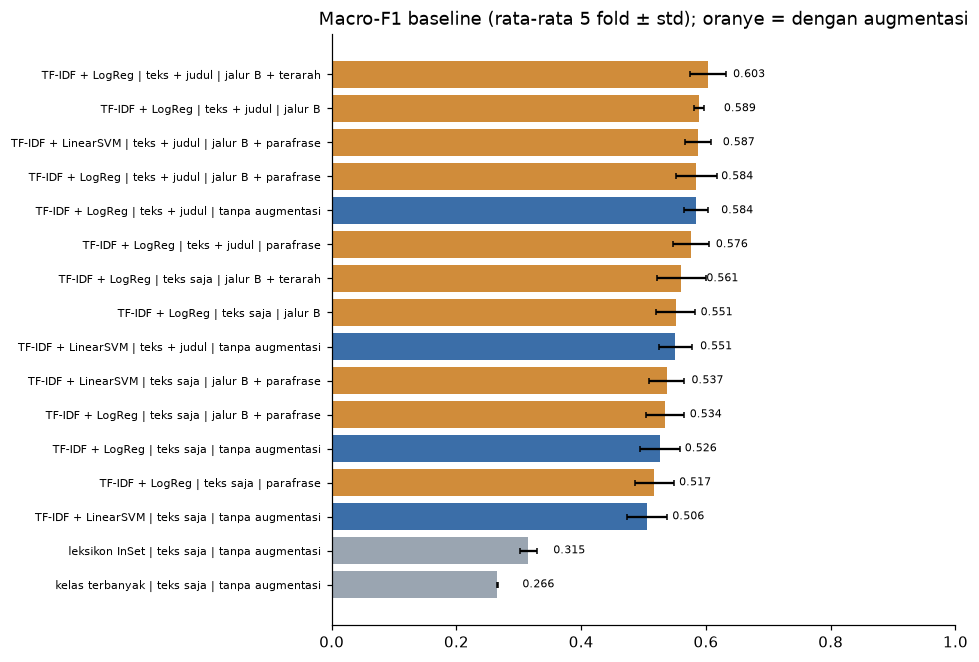

In [15]:
data = sorted([(f"{n} | {i} | {v}", t.macro_f1.mean(), t.macro_f1.std()) for (n, i, v), t in hasil.items()],
              key=lambda x: x[1])
fig, ax = plt.subplots(figsize=(9, 0.32 * len(data) + 1))
nama, rata, sd = zip(*data)
warna = ["#9aa5b1" if "terbanyak" in n or "InSet" in n else "#d08c3a" if "tanpa augmentasi" not in n else "#3b6ea8"
         for n in nama]
ax.barh(nama, rata, xerr=sd, color=warna, capsize=2)
for y, v in enumerate(rata):
    ax.text(v + 0.04, y, f"{v:.3f}", va="center", fontsize=7)
ax.set(title="Macro-F1 baseline (rata-rata 5 fold ± std); oranye = dengan augmentasi", xlim=(0, 1))
ax.tick_params(axis="y", labelsize=7)
plt.tight_layout()
plt.savefig(FIG / "02_macro_f1_baseline.png", bbox_inches="tight")
plt.show()

Grafik ini merangkum tabel di atas. Batang abu-abu adalah dua baseline tanpa pembelajaran, biru tanpa augmentasi, dan oranye dengan augmentasi. Konfigurasi teks + judul selalu berada di atas teks saja, dan selisih antar varian augmentasi lebih kecil daripada selisih karena judul.

## Ablation: dampak tiap langkah preprocessing

Selain augmentasi, setiap langkah preprocessing juga perlu dicek dampaknya. Modelnya dibuat tetap (TF-IDF + LogReg, teks saja, tanpa augmentasi), lalu langkah preprocessing ditambah satu per satu. Baris terakhir menghapus class weight untuk melihat dampaknya.

In [16]:
clf, grid, _ = MODEL["TF-IDF + LogReg"]
baris = []
for nama_v, kolom in versi.items():
    Xa = pd.DataFrame({"teks": df[kolom], "judul": df.judul_lengkap})
    t, _ = evaluasi(lambda: Pipeline([("fitur", fitur(False)), ("clf", clf())]), Xa, grid=grid)
    baris.append({"preprocessing": nama_v, "macro-F1": f"{t.macro_f1.mean():.3f} ± {t.macro_f1.std():.3f}",
                  "F1 positif": round(t.f1_positif.mean(), 3), "F1 netral": round(t.f1_netral.mean(), 3)})
t, _ = evaluasi(lambda: Pipeline([("fitur", fitur(False)), ("clf", LogisticRegression(max_iter=3000))]), X, grid=grid)
baris.append({"preprocessing": "versi utama, TANPA class weight", "macro-F1": f"{t.macro_f1.mean():.3f} ± {t.macro_f1.std():.3f}",
              "F1 positif": round(t.f1_positif.mean(), 3), "F1 netral": round(t.f1_netral.mean(), 3)})
pd.DataFrame(baris)

,preprocessing,macro-F1,F1 positif,F1 netral
0,ringan + lowercase,0.545 ± 0.037,0.250,0.594
1,"+ emoji, tawa, slang",0.552 ± 0.036,0.278,0.592
2,+ buang stopword (versi utama),0.526 ± 0.032,0.206,0.593
3,+ stemming,0.535 ± 0.027,0.223,0.599
4,"versi utama, TANPA class weight",0.483 ± 0.029,0.062,0.566


Keempat versi preprocessing hampir sama (0,526 sampai 0,552), dan perbedaannya lebih kecil dari standar deviasi antar fold (0,027 sampai 0,037). Versi "+ emoji, tawa, slang" sedikit paling tinggi (0,552), sedangkan membuang stopword justru menurunkan skor sedikit (0,526). Jadi untuk TF-IDF dengan n-gram huruf, langkah normalisasi tambahan tidak memberi dampak yang bisa dipastikan. Yang dampaknya jelas adalah **class weight**: tanpa class weight macro-F1 turun menjadi 0,483 dan F1 positif tinggal 0,062, karena model hampir tidak pernah menebak positif.

In [17]:
semua = [t.assign(model=n, input=i, augmentasi=v) for (n, i, v), t in hasil.items()]
pd.concat(semua, ignore_index=True).to_csv(HASIL / "hasil_per_fold.csv", index=False)
pd.DataFrame({"id": df.id, "label": df.label, **{f"{n} | {i} | {v}": p.values for (n, i, v), p in prediksi.items()}}
             ).to_csv(HASIL / "prediksi_oof.csv", index=False)
print("tersimpan:", len(hasil), "konfigurasi")

tersimpan: 16 konfigurasi


Semua hasil disimpan di `data/06_baseline/`. `hasil_per_fold.csv` berisi skor tiap konfigurasi di tiap fold, dan `prediksi_oof.csv` berisi prediksi setiap konfigurasi untuk semua teks (setiap teks diprediksi saat menjadi data uji). Berkas ini dipakai notebook 05 untuk membandingkan semua model dan menganalisis kesalahan.

## Kesimpulan

Baseline terbaik adalah TF-IDF + LogReg dengan teks + judul dan augmentasi jalur B (macro-F1 0,589 ± 0,009), praktis setara dengan Linear SVM teks + judul + augmentasi lengkap (0,587 ± 0,021) dan LogReg teks + judul tanpa augmentasi (0,584 ± 0,019). Ketiganya jauh di atas tebak kelas terbanyak (0,266) dan leksikon InSet (0,315).

Dampak setiap metode yang diuji:

- **Judul** adalah tambahan yang paling berpengaruh: +0,058 untuk LogReg dan +0,045 untuk SVM tanpa augmentasi.
- **Augmentasi** membantu model yang lemah di kelas positif (SVM: +0,031 sampai +0,036, F1 positif +0,09 sampai +0,11) dan LogReg teks saja dengan jalur B (+0,025, membaik di 5 dari 5 fold), tapi hampir tidak mengubah LogReg teks + judul. Jalur B lebih aman daripada parafrase, karena parafrase back-translation membawa sekitar 17% makna yang rusak atau berbalik.
- **Class weight** penting: tanpanya macro-F1 turun 0,043 dan F1 positif turun dari 0,206 ke 0,062.
- **Langkah preprocessing** (slang, stopword, stemming) tidak memberi perbedaan yang melebihi variasi antar fold.

Kelas positif tetap yang paling lemah (F1 sekitar 0,27 sampai 0,30). TF-IDF hanya menghitung kata, jadi pembelaan yang ditulis dengan nada marah ke pengkritik Raffi tetap terbaca negatif. Notebook 03 dan 04 menguji model yang membaca kalimat secara utuh.